In [43]:
import os
from typing import List, Optional, Tuple
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from Bio import SeqIO
from matplotlib.colors import to_rgb, to_hex
from matplotlib.collections import LineCollection
from matplotlib.legend_handler import HandlerTuple
from matplotlib.lines import Line2D
import baltic as bt

In [76]:
SERO = range(1, 5)
plt.rcParams['font.family'] = 'sans-serif'

# Paleta Okabe-Ito: pasa validación de daltonismo (deutan/protan/tritan).
SERO_COLORS = {
    1: "#D55E00",  # DENV1
    2: "#009E73",  # DENV2
    3: "#56B4E9",  # DENV3
    4: "#CC79A7"   # DENV4
}

TYPE_INTENSITY = {
    "COL": 1.0,
    "EXP": 0.2,
    "MAP": 1.4
}

COLOR_UNKNOWN = "#888888"

In [34]:
TIME_TREE_MERGE = "../resources/merged_data/refined/E_DENV{}_tree_time.nwk"
META_MERGE = "../resources/merged_data/metadata/merged_DENV{}_meta.tsv"

AA_SEQS_COL_E = "../resources/colombia_data/AA_sequences/E_DENV{}_aa_E.fasta"
AA_SEQS_EXP_E = "../resources/experimental_data/AA_sequences/E_DENV{}_aa_E.fasta"
AA_SEQS_EXP_E_MAP = "../resources/experimental_data/AA_sequences/E_DENV{}_aa_E_map.fasta"

DIST_EPITOPE_GRANTHAM = "../output/distances_epitope_grantham_DENV{sero}.csv"
DIST_EPITOPE_GRANTHAM_VAL = "../output/validation_distances_epitope_grantham_DENV{sero}.csv"
DIST_ALL_GRANTHAM_VAL = "../output/validation_distances_all_grantham_DENV{sero}.csv"
DIST_EPITOPE_HAMMING_VAL = "../output/validation_distances_epitope_hamming_DENV{sero}.csv"
DIST_ALL_HAMMING_VAL = "../output/validation_distances_all_hamming_DENV{sero}.csv"

## Cargar mapa antigénico

In [37]:
mapa_ag = pd.read_csv(
    "../resources/experimental_data/2d-antigenic-map.txt",
    sep=r"\s+",
    header=None,
    names=["type", "strainID", "coord1", "coord2"]
)

# Extraer serotipo: acepta DENV1 y DEN1
mapa_ag["sero_num"] = mapa_ag["strainID"].str.extract(
    r"(?:DENV|DEN)(\d)",
    expand=False
)

mapa_ag["sero"] = "DENV" + mapa_ag["sero_num"]

antigenos = mapa_ag[mapa_ag["type"] == "AG"].copy()
sueros = mapa_ag[mapa_ag["type"] == "SR"].copy()

print(f"Antígenos: {len(antigenos)}")
print(f"Antisueros: {len(sueros)}")

### Secuencias de referencia que se encuentran en el mapa

In [38]:
valid_strain_ids = set(mapa_ag['strainID'].astype(str).tolist())
print(f"Total de cepas de referencia válidas en mapa_ag: {len(valid_strain_ids)}")

serotypes = [1, 2, 3, 4]

print("\nFiltrando secuencias experimentales...")
for sero in serotypes:
    input_fasta = AA_SEQS_EXP_E.format(sero)
    output_fasta = AA_SEQS_EXP_E_MAP.format(sero)
    
    all_records = list(SeqIO.parse(input_fasta, "fasta"))
    total_seqs = len(all_records)
    
    filtered_records = [r for r in all_records if r.id in valid_strain_ids]
    kept_seqs = len(filtered_records)
    
    SeqIO.write(filtered_records, output_fasta, "fasta")
    
    print(f"  DENV{sero}: Conservadas {kept_seqs} / {total_seqs} secuencias.")
    print(f"          -> Guardado en: {output_fasta}")

Total de cepas de referencia válidas en mapa_ag: 448

Filtrando secuencias experimentales...
  DENV1: Conservadas 105 / 1316 secuencias.
          -> Guardado en: ../resources/experimental_data/AA_sequences/E_DENV1_aa_E_map.fasta
  DENV2: Conservadas 86 / 871 secuencias.
          -> Guardado en: ../resources/experimental_data/AA_sequences/E_DENV2_aa_E_map.fasta
  DENV3: Conservadas 102 / 928 secuencias.
          -> Guardado en: ../resources/experimental_data/AA_sequences/E_DENV3_aa_E_map.fasta
  DENV4: Conservadas 92 / 740 secuencias.
          -> Guardado en: ../resources/experimental_data/AA_sequences/E_DENV4_aa_E_map.fasta


### Figura: Árboles filogenéticos por serotipo

In [52]:
def get_serotype_colors(sero):

    base = to_rgb(SERO_COLORS[sero])

    def shade(color, intensity):
        if intensity <= 1:
            # Mezcla con blanco
            return to_hex(
                tuple(
                    1 - intensity * (1 - c)
                    for c in color
                )
            )
        # Mezcla con negro
        return to_hex(
            tuple(
                c * (2 - intensity)
                for c in color
            )
        )

    return {
        "COL": shade(
            base, TYPE_INTENSITY["COL"]
        ),
        "EXP": shade(
            base, TYPE_INTENSITY["EXP"]
        ),
        "MAP": shade(
            base, TYPE_INTENSITY["MAP"]
        )
    }



DENV 1
Secuencias en FASTA del mapa: 105
Experimentales en mapa: 105
Ejemplos: ['DENV1/THAILAND/2012/00777/12', 'DENV1/THAILAND/1983/00493/83', 'DENV1/THAILAND/1998/00422/98', 'DENV1/THAILAND/1999/03739/99', 'DENV1/THAILAND/2006/00007/06']

DENV 2
Secuencias en FASTA del mapa: 86
Experimentales en mapa: 86
Ejemplos: ['DENV2/THAILAND/2000/00342/00', 'DENV2/THAILAND/1996/01163/96', 'DENV2/THAILAND/2004/00248/04', 'DENV2/THAILAND/1996/01309/96', 'DENV2/THAILAND/2002/02678/02']

DENV 3
Secuencias en FASTA del mapa: 102
Experimentales en mapa: 102
Ejemplos: ['DENV3/CAMBODIA/2007/FJ639714', 'DENV3/THAILAND/1998/02434/98', 'DENV3/THAILAND/2012/00817/12', 'DENV3/THAILAND/1998/06070/98', 'DENV3/THAILAND/2006/01375/06']

DENV 4
Secuencias en FASTA del mapa: 92
Experimentales en mapa: 92
Ejemplos: ['DENV4/THAILAND/2005/00201/05', 'DENV4/THAILAND/2007/01840/07', 'DENV4/THAILAND/2007/00119/07', 'DENV4/THAILAND/2011/00251/11', 'DENV4/THAILAND/2014/00555/14']


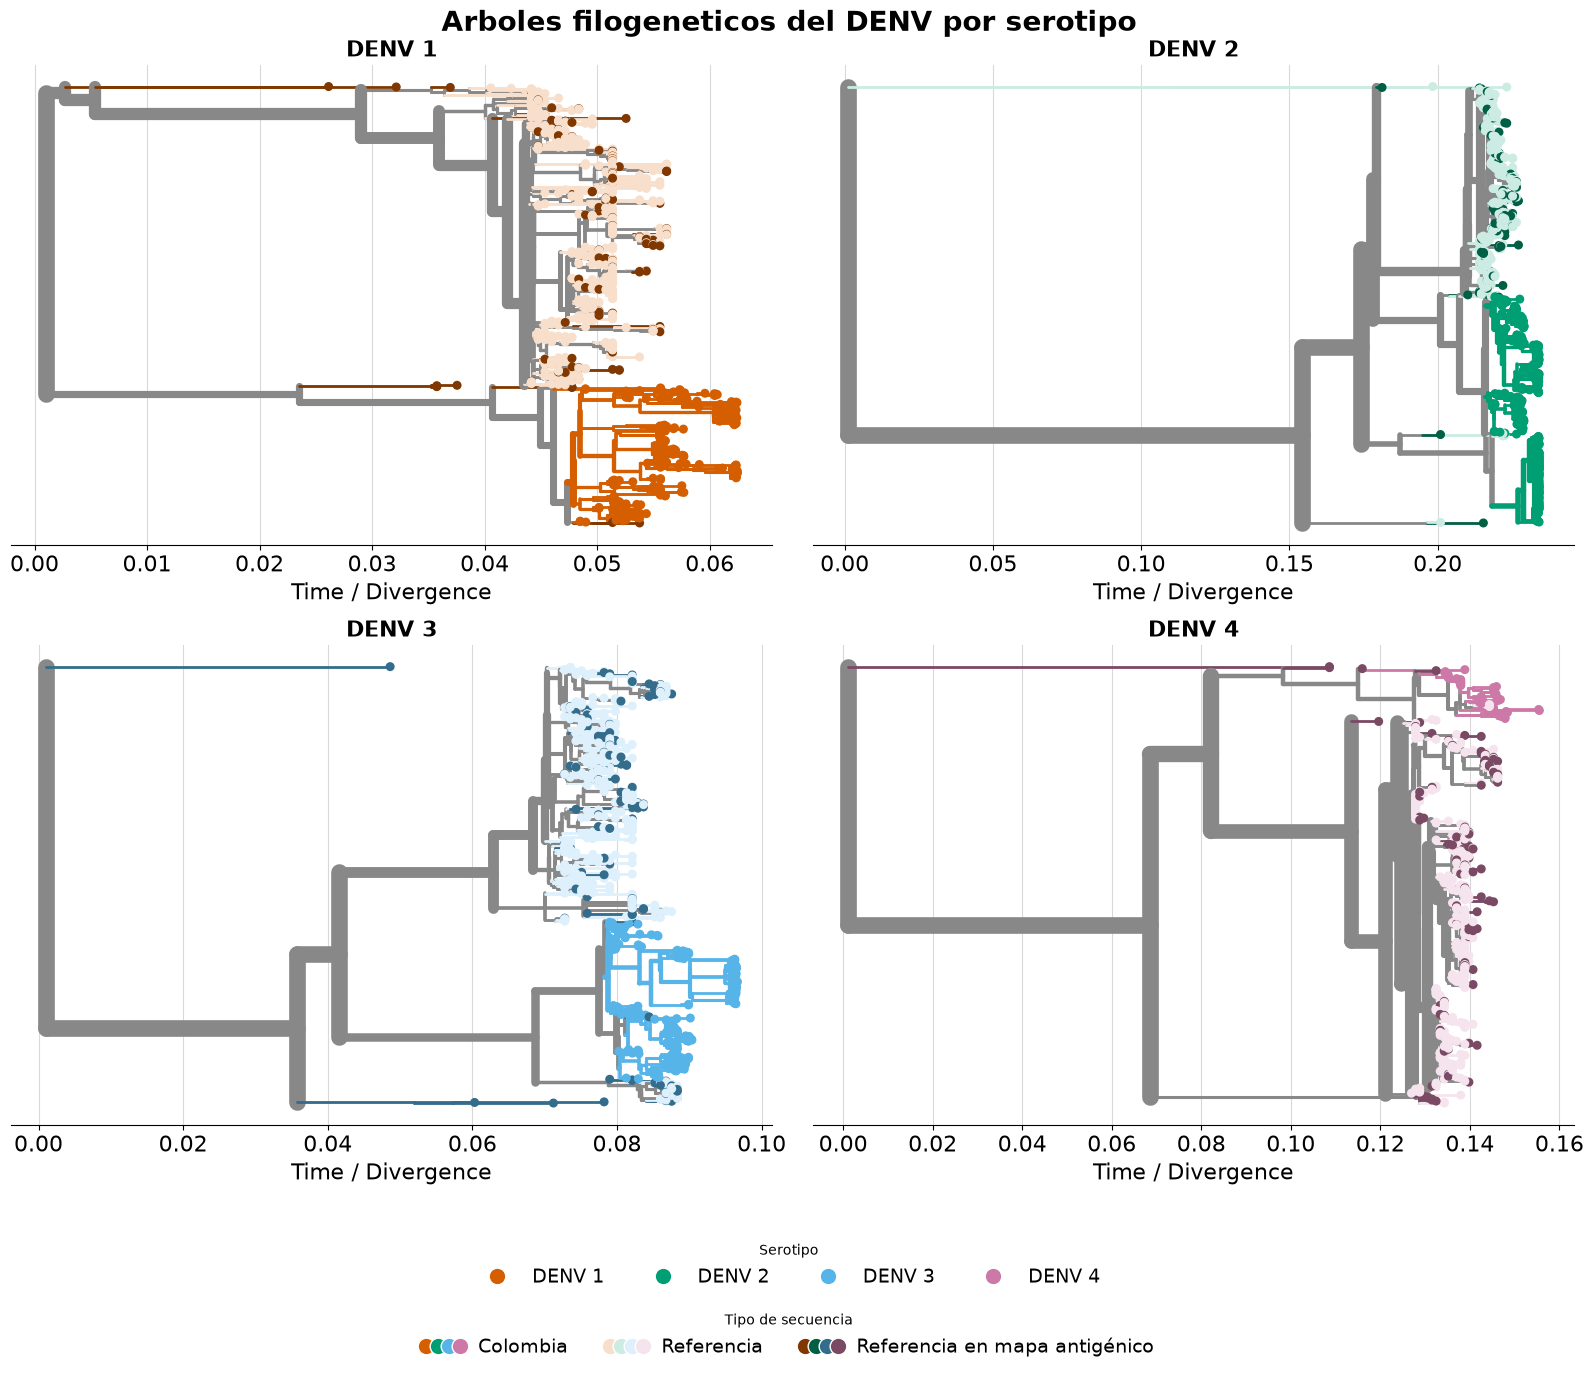

In [67]:
def clean_id(x):
    """
    Limpia un identificador sin dividirlo en tokens.
    """
    return str(x).strip()


def get_fasta_ids(fasta_path):
    """
    Obtiene los IDs completos de las secuencias del FASTA.
    """
    return {
        clean_id(record.id)
        for record in SeqIO.parse(fasta_path, "fasta")
    }


def draw_tree(ax, tree, colour, width, size=30, zorder=20000):
    """
    Dibuja el árbol con matplotlib a partir de k.x / k.y de baltic.
    No depende de Tree.plotTree / Tree.plotPoints, que no existen
    en todas las versiones de baltic.
    """
    segs, seg_c, seg_w = [], [], []
    tip_x, tip_y, tip_c = [], [], []

    for k in tree.Objects:

        x, y = k.x, k.y
        x_parent = getattr(getattr(k, 'parent', None), 'x', None)
        if x_parent is None:
            x_parent = x

        c = colour(k)
        w = width(k)

        # Rama horizontal (padre -> nodo)
        segs.append([(x_parent, y), (x, y)])
        seg_c.append(c)
        seg_w.append(w)

        if k.branchType == 'node':
            # Conector vertical entre hijos
            ys = [ch.y for ch in k.children]
            segs.append([(x, min(ys)), (x, max(ys))])
            seg_c.append(c)
            seg_w.append(w)
        else:
            tip_x.append(x)
            tip_y.append(y)
            tip_c.append(c)

    ax.add_collection(
        LineCollection(
            segs,
            colors=seg_c,
            linewidths=seg_w,
            capstyle='round',
            zorder=zorder
        )
    )

    ax.scatter(
        tip_x, tip_y,
        s=size,
        c=tip_c,
        zorder=zorder + 2
    )

    ax.autoscale_view()


fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flatten()


for idx, s in enumerate(range(4)):

    sero = s + 1
    ax = axes[idx]

    SEROTYPE_COLORS = get_serotype_colors(sero)

    COLOR_COL = SEROTYPE_COLORS["COL"]
    COLOR_EXP = SEROTYPE_COLORS["EXP"]
    COLOR_MAP = SEROTYPE_COLORS["MAP"]

    ll = bt.load_newick(TIME_TREE_MERGE.format(sero), treeType="time")

    df = pd.read_csv(
        META_MERGE.format(sero),
        sep='\t'
    )

    df['country'] = (
        df['country']
        .fillna('')
        .str.strip()
        .str.lower()
    )

    map_fasta = AA_SEQS_EXP_E_MAP.format(sero)

    map_ids = get_fasta_ids(map_fasta)

    print(f"\nDENV {sero}")
    print(f"Secuencias en FASTA del mapa: {len(map_ids)}")

    origin_map = {}

    for _, row in df.iterrows():

        strain = clean_id(row['strain'])

        if 'colombia' in row['country']:
            origin = 'COL'
        else:
            origin = 'EXP'

        origin_map[strain] = origin

    experimental_map_ids = set()

    for strain, origin in origin_map.items():

        if origin == 'EXP' and strain in map_ids:
            experimental_map_ids.add(strain)

    print(
        f"Experimentales en mapa: "
        f"{len(experimental_map_ids)}"
    )

    # Mostrar algunas para verificar
    print(
        "Ejemplos:",
        list(experimental_map_ids)[:5]
    )

    leaf_colors = {}

    for k in ll.Objects:

        if k.branchType != 'leaf':
            continue

        name = clean_id(k.name)

        if origin_map.get(name) == 'COL':

            leaf_colors[name] = COLOR_COL

        elif origin_map.get(name) == 'EXP':

            if name in experimental_map_ids:
                leaf_colors[name] = COLOR_MAP
            else:
                leaf_colors[name] = COLOR_EXP

        else:

            leaf_colors[name] = COLOR_UNKNOWN

    def c_func(k):

        if k.branchType == 'leaf':
            return leaf_colors.get(
                clean_id(k.name),
                COLOR_UNKNOWN
            )

        has_col = False
        has_exp = False
        has_map = False

        for d in k.leaves:

            d_name = d.name if hasattr(d, 'name') else d

            c = leaf_colors.get(
                clean_id(d_name),
                COLOR_UNKNOWN
            )

            if c == COLOR_COL:
                has_col = True

            elif c == COLOR_EXP:
                has_exp = True

            elif c == COLOR_MAP:
                has_map = True

        # Si hay más de un tipo dentro del clado,
        # dejamos la rama gris
        n_types = sum([
            has_col,
            has_exp,
            has_map
        ])

        if n_types > 1:
            return COLOR_UNKNOWN

        if has_col:
            return COLOR_COL

        if has_map:
            return COLOR_MAP

        if has_exp:
            return COLOR_EXP

        return COLOR_UNKNOWN

    L = sum(
        1
        for k in ll.Objects
        if k.branchType == 'leaf'
    )

    b_func = lambda k: (
        2 + 10.0 * len(k.leaves) / L
        if k.branchType == 'node'
        else 2
    )

    draw_tree(
        ax,
        ll,
        colour=c_func,
        width=b_func,
        size=30
    )

    for loc in ['left', 'right', 'top']:
        ax.spines[loc].set_visible(False)

    ax.grid(
        axis='x',
        ls='-',
        color='grey',
        alpha=0.3
    )

    ax.tick_params(
        axis='y',
        size=0
    )

    ax.tick_params(
        axis='x',
        labelsize=16
    )

    ax.set_xlabel(
        'Time / Divergence',
        fontsize=16
    )

    ax.set_yticklabels([])

    ax.set_title(
        f"DENV {sero}",
        fontsize=16,
        fontweight='bold'
    )

fig.suptitle(
    "Arboles filogeneticos del DENV por serotipo",
    fontsize=20,
    fontweight='bold',
    y=0.98
)


# Leyenda de serotipos
sero_legend = [
    Line2D(
        [0], [0],
        marker='o',
        color='w',
        label=f'DENV {sero}',
        markerfacecolor=SERO_COLORS[sero],
        markersize=12
    )
    for sero in range(1, 5)
]

# Leyenda de tipos de secuencia: cada entrada muestra
# el tono de get_serotype_colors para los cuatro serotipos
TYPE_LABELS = {
    "COL": "Colombia",
    "EXP": "Referencia",
    "MAP": "Referencia en mapa antigénico"
}

type_handles = [
    tuple(
        Line2D(
            [0], [0],
            marker='o',
            color='w',
            markerfacecolor=get_serotype_colors(sero)[t],
            markersize=12
        )
        for sero in range(1, 5)
    )
    for t in TYPE_LABELS
]

fig.legend(
    handles=sero_legend,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.055),
    fontsize=14,
    ncol=4,
    frameon=False,
    title='Serotipo'
)

fig.legend(
    handles=type_handles,
    labels=list(TYPE_LABELS.values()),
    handler_map={tuple: HandlerTuple(ndivide=None, pad=0.3)},
    loc='lower center',
    bbox_to_anchor=(0.5, 0.005),
    fontsize=14,
    ncol=3,
    frameon=False,
    title='Tipo de secuencia'
)

plt.tight_layout(rect=[0, 0.13, 1, 1])


plt.savefig(
    "../figures/DENV_all_serotypes_col_exp.jpeg",
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()

## Distancias

### Distancia de Hamming

In [5]:
def hamming_distance(s1, s2):
    if len(s1) != len(s2):
        raise ValueError("Strings must be of the same length")
    
    return sum(el1 != el2 for el1, el2 in zip(s1, s2))

### Distancia de Grantham

In [6]:
def grantham_distance(s1, s2):
    grantham_matrix = {
      'A': {'A':0,'R':112,'N':111,'D':126,'C':195,'Q':91,'E':107,'G':60,'H':86,'I':94,'L':96,'K':106,'M':84,'F':113,'P':27,'S':99,'T':58,'W':148,'Y':112,'V':64},
      'R': {'A':112,'R':0,'N':86,'D':96,'C':180,'Q':43,'E':54,'G':125,'H':29,'I':97,'L':102,'K':26,'M':91,'F':97,'P':103,'S':110,'T':71,'W':101,'Y':77,'V':96},
      'N': {'A':111,'R':86,'N':0,'D':23,'C':139,'Q':46,'E':42,'G':80,'H':68,'I':149,'L':153,'K':94,'M':142,'F':158,'P':91,'S':46,'T':65,'W':174,'Y':143,'V':133},
      'D': {'A':126,'R':96,'N':23,'D':0,'C':154,'Q':61,'E':45,'G':94,'H':81,'I':168,'L':172,'K':101,'M':160,'F':177,'P':108,'S':65,'T':85,'W':181,'Y':160,'V':152},
      'C': {'A':195,'R':180,'N':139,'D':154,'C':0,'Q':154,'E':170,'G':159,'H':174,'I':198,'L':198,'K':202,'M':196,'F':205,'P':169,'S':112,'T':149,'W':215,'Y':194,'V':192},
      'Q': {'A':91,'R':43,'N':46,'D':61,'C':154,'Q':0,'E':29,'G':87,'H':24,'I':109,'L':113,'K':53,'M':101,'F':116,'P':76,'S':68,'T':42,'W':130,'Y':99,'V':96},
      'E': {'A':107,'R':54,'N':42,'D':45,'C':170,'Q':29,'E':0,'G':98,'H':40,'I':134,'L':138,'K':56,'M':126,'F':140,'P':93,'S':80,'T':65,'W':152,'Y':122,'V':121},
      'G': {'A':60,'R':125,'N':80,'D':94,'C':159,'Q':87,'E':98,'G':0,'H':98,'I':135,'L':138,'K':127,'M':127,'F':153,'P':42,'S':56,'T':59,'W':184,'Y':147,'V':109},
      'H': {'A':86,'R':29,'N':68,'D':81,'C':174,'Q':24,'E':40,'G':98,'H':0,'I':94,'L':99,'K':32,'M':87,'F':100,'P':77,'S':89,'T':47,'W':115,'Y':83,'V':84},
      'I': {'A':94,'R':97,'N':149,'D':168,'C':198,'Q':109,'E':134,'G':135,'H':94,'I':0,'L':5,'K':102,'M':10,'F':21,'P':95,'S':142,'T':89,'W':61,'Y':33,'V':29},
      'L': {'A':96,'R':102,'N':153,'D':172,'C':198,'Q':113,'E':138,'G':138,'H':99,'I':5,'L':0,'K':107,'M':15,'F':22,'P':98,'S':145,'T':92,'W':61,'Y':36,'V':32},
      'K': {'A':106,'R':26,'N':94,'D':101,'C':202,'Q':53,'E':56,'G':127,'H':32,'I':102,'L':107,'K':0,'M':95,'F':102,'P':103,'S':121,'T':78,'W':110,'Y':85,'V':97},
      'M': {'A':84,'R':91,'N':142,'D':160,'C':196,'Q':101,'E':126,'G':127,'H':87,'I':10,'L':15,'K':95,'M':0,'F':28,'P':87,'S':135,'T':81,'W':67,'Y':36,'V':21},
      'F': {'A':113,'R':97,'N':158,'D':177,'C':205,'Q':116,'E':140,'G':153,'H':100,'I':21,'L':22,'K':102,'M':28,'F':0,'P':114,'S':155,'T':103,'W':40,'Y':22,'V':50},
      'P': {'A':27,'R':103,'N':91,'D':108,'C':169,'Q':76,'E':93,'G':42,'H':77,'I':95,'L':98,'K':103,'M':87,'F':114,'P':0,'S':74,'T':38,'W':147,'Y':110,'V':68},
      'S': {'A':99,'R':110,'N':46,'D':65,'C':112,'Q':68,'E':80,'G':56,'H':89,'I':142,'L':145,'K':121,'M':135,'F':155,'P':74,'S':0,'T':58,'W':177,'Y':144,'V':124},
      'T': {'A':58,'R':71,'N':65,'D':85,'C':149,'Q':42,'E':65,'G':59,'H':47,'I':89,'L':92,'K':78,'M':81,'F':103,'P':38,'S':58,'T':0,'W':128,'Y':92,'V':69},
      'W': {'A':148,'R':101,'N':174,'D':181,'C':215,'Q':130,'E':152,'G':184,'H':115,'I':61,'L':61,'K':110,'M':67,'F':40,'P':147,'S':177,'T':128,'W':0,'Y':37,'V':88},
      'Y': {'A':112,'R':77,'N':143,'D':160,'C':194,'Q':99,'E':122,'G':147,'H':83,'I':33,'L':36,'K':85,'M':36,'F':22,'P':110,'S':144,'T':92,'W':37,'Y':0,'V':55},
      'V': {'A':64,'R':96,'N':133,'D':152,'C':192,'Q':96,'E':121,'G':109,'H':84,'I':29,'L':32,'K':97,'M':21,'F':50,'P':68,'S':124,'T':69,'W':88,'Y':55,'V':0}
   }
    
    if len(s1) != len(s2):
        raise ValueError("Sequences must be of the same length")

    distance = 0

    for aa1, aa2 in zip(s1, s2):
        if aa1 == "-" or aa2 == "-":
            continue
        if aa1 == "*" or aa2 == "*":
            continue
        if aa1 not in grantham_matrix or aa2 not in grantham_matrix[aa1]:
            continue
        distance += grantham_matrix[aa1][aa2]
    return distance

### Distancia antigénica p-all-epitope

In [83]:
E_LEN_STD = 495   # longitud del gen E en DENV1, DENV2 y DENV4
DENV3_GAP = 157   # indice 0-based donde DENV3 pierde los residuos 158-159


def _to_std_numbering(seq):
    """Lleva una secuencia a la numeracion comun de DENV1/2/4.

    DENV3 tiene dos residuos menos por una delecion en las posiciones
    158-159, de modo que se insertan dos huecos para que las cuatro
    serotipos compartan el mismo sistema de coordenadas. Asi la posicion
    k significa lo mismo en cualquier par de secuencias, tambien cuando
    se comparan serotipos distintos.
    """
    if len(seq) == E_LEN_STD - 2:
        return seq[:DENV3_GAP] + "--" + seq[DENV3_GAP:]
    return seq


def antigenic_distance(s1, s2, sero=None, type='grantham'):
    """Distancia antigenica p-all-epitope entre dos secuencias del gen E.

    El serotipo se deduce de cada secuencia por separado (ver
    _to_std_numbering), por lo que el argumento `sero` se mantiene
    unicamente por compatibilidad con llamadas previas y no se utiliza.
    """
    s1 = _to_std_numbering(s1)
    s2 = _to_std_numbering(s2)

    # Posiciones en numeracion 1-based de DENV1/2/4 (convencion de la literatura)
    locations_EDI = [
        [47, 47], [123, 126], [148, 165], [167, 167],
        [170, 177], [180, 180], [279, 279], [293, 293]
    ]
    locations_EDII = [
        [67, 74], [76, 79], [88, 88], [97, 118],
        [215, 215], [219, 219], [233, 233], [237, 237],
        [244, 249], [256, 256], [266, 268], [272, 276]
    ]
    locations_EDIII = [
        [282, 282], [298, 311], [314, 370],
        [372, 372], [382, 385], [387, 390]
    ]

    def _domain_distance(locations):
        total_dist = 0
        n_residues = 0
        for start, end in locations:
            # Conversion de 1-based inclusivo a slicing 0-based: [start-1 : end]
            a, b = s1[start - 1:end], s2[start - 1:end]
            # Se ignoran las columnas con hueco o stop en cualquiera de las dos,
            # tanto en el numerador como en el denominador: los dos huecos de
            # DENV3 no cuentan como diferencias ni diluyen la normalizacion.
            pairs = [(x, y) for x, y in zip(a, b)
                     if x not in "-*" and y not in "-*"]
            if not pairs:
                continue
            c1 = "".join(x for x, _ in pairs)
            c2 = "".join(y for _, y in pairs)
            if type == 'grantham':
                total_dist += grantham_distance(c1, c2)
            else:
                total_dist += hamming_distance(c1, c2)
            n_residues += len(pairs)
        return total_dist, n_residues

    sum_dist_EDI,   n_EDI   = _domain_distance(locations_EDI)
    sum_dist_EDII,  n_EDII  = _domain_distance(locations_EDII)
    sum_dist_EDIII, n_EDIII = _domain_distance(locations_EDIII)

    w = 215 if type == 'grantham' else 1

    # Ec. 2: E_i = (sum G_k) / (n_i * 215) * 20, por dominio
    E_EDI   = (sum_dist_EDI   / (n_EDI   * w)) * 20
    E_EDII  = (sum_dist_EDII  / (n_EDII  * w)) * 20
    E_EDIII = (sum_dist_EDIII / (n_EDIII * w)) * 20

    # Ec. 3: promedio de los tres dominios
    epit_dist = (E_EDI + E_EDII + E_EDIII) / 3
    return epit_dist

### Validar Corte de regiones epitópicas

In [84]:
def get(sero):
    return str(next(iter(SeqIO.parse(AA_SEQS_EXP_E_MAP.format(sero), "fasta"))).seq)

def chk(sero, sites):
    s = get(sero)
    off = lambda p: p - 2 if (sero == 3 and p > 159) else p   # deleción DENV3
    for p, aa in sites.items():
        q = off(p)
        print(f"DENV{sero} {aa}{p}: 1-based={s[q-1]} | 0-based={s[q]}  "
              f"{'OK' if s[q-1]==aa else '--'}")

# DENV2 (filas DV2-44, DV2-76, 3H2/2C8, 1A1D-2)
chk(2, {88:'K', 233:'Q', 244:'H', 282:'V', 309:'V', 310:'K',
        361:'K', 383:'E', 384:'P'})

# J8/J9, DENV1-4: K47, H149, V151, F279
for sero in [1, 2, 3, 4]:
    chk(sero, {47:'K', 149:'H', 151:'V', 279:'F'})

# DENV4, 1G6: 387-ALTLH-390 con T388 y H390
s4 = get(4)
print("DENV4 s[385:390] =", s4[385:390], "(esperado ALTLH, posiciones 386-390)")

DENV2 K88: 1-based=K | 0-based=R  OK
DENV2 Q233: 1-based=Q | 0-based=K  OK
DENV2 H244: 1-based=H | 0-based=A  OK
DENV2 V282: 1-based=H | 0-based=L  --
DENV2 V309: 1-based=V | 0-based=K  OK
DENV2 K310: 1-based=K | 0-based=E  OK
DENV2 K361: 1-based=K | 0-based=D  OK
DENV2 E383: 1-based=E | 0-based=P  OK
DENV2 P384: 1-based=P | 0-based=G  OK
DENV1 K47: 1-based=K | 0-based=T  OK
DENV1 H149: 1-based=H | 0-based=Q  OK
DENV1 V151: 1-based=V | 0-based=G  OK
DENV1 F279: 1-based=F | 0-based=A  OK
DENV2 K47: 1-based=K | 0-based=T  OK
DENV2 H149: 1-based=H | 0-based=A  OK
DENV2 V151: 1-based=V | 0-based=G  OK
DENV2 F279: 1-based=F | 0-based=T  OK
DENV3 K47: 1-based=K | 0-based=T  OK
DENV3 H149: 1-based=H | 0-based=Q  OK
DENV3 V151: 1-based=V | 0-based=G  OK
DENV3 F279: 1-based=F | 0-based=A  OK
DENV4 K47: 1-based=K | 0-based=T  OK
DENV4 H149: 1-based=H | 0-based=A  OK
DENV4 V151: 1-based=V | 0-based=G  OK
DENV4 F279: 1-based=F | 0-based=A  OK
DENV4 s[385:390] = ALTLH (esperado ALTLH, posiciones 38

## Calculo de matriz de distancias antigénicas

In [85]:
def _load_filtered_fasta(path: str, exclude_prefix: str) -> Tuple[List[str], List[str]]:
    """Lee un FASTA y devuelve (ids, secuencias), excluyendo IDs con cierto prefijo."""
    records = [
        r for r in SeqIO.parse(path, "fasta")
        if not r.id.startswith(exclude_prefix)
    ]
    return [r.id for r in records], [str(r.seq) for r in records]


def compute_distance_matrices(
    fasta_col_template: str,
    fasta_exp_template: str,
    exclude_prefix: str = "NODE",
    metric: str = "grantham",
) -> List[pd.DataFrame]:
    """Una matriz de distancias (colombianas x experimentales) por serotipo."""
    serotypes = [1, 2, 3, 4]

    # Referencias experimentales unificadas (todos los serotipos)
    ids_exp, seqs_exp = [], []
    for sero in serotypes:
        ids, seqs = _load_filtered_fasta(fasta_exp_template.format(sero), exclude_prefix)
        ids_exp.extend(ids)
        seqs_exp.extend(seqs)
    print(f"Conjunto unificado de referencias experimentales: {len(seqs_exp)} secuencias")

    matrices = []
    for sero in serotypes:
        print(f"Procesando DENV{sero}...")
        ids_col, seqs_col = _load_filtered_fasta(fasta_col_template.format(sero), exclude_prefix)

        matrix = np.full((len(seqs_col), len(seqs_exp)), np.nan)
        for i, seq_col in enumerate(seqs_col):
            for j, seq_exp in enumerate(seqs_exp):
                matrix[i, j] = antigenic_distance(seq_col, seq_exp, sero, type=metric)
        matrices.append(pd.DataFrame(matrix, index=ids_col, columns=ids_exp))

    return matrices


In [86]:
def _pad_denv3(seq: str) -> str:
    """DENV3 tiene dos residuos menos: deleción en 158-159 (numeración DENV1/2/4).
    Se insertan dos huecos para que los cuatro serotipos compartan numeración."""
    return seq[:157] + "--" + seq[157:]


def gene_distance(s1: str, s2: str, type: str = "grantham") -> float:
    """Distancia sobre todo el gen E, sin recortar a los sitios epitópicos.

    Se normaliza igual que la Ec. 2 (dividir por n y por el máximo de la métrica,
    escalar por 20) para que quede en la misma escala que la distancia epitópica
    y sirva como modelo nulo. Las columnas con hueco o stop se ignoran en ambas
    métricas, así que los dos huecos de DENV3 no cuentan como diferencias.
    """
    pairs = [(a, b) for a, b in zip(s1, s2)
             if a not in "-*" and b not in "-*"]
    if not pairs:
        return np.nan

    c1 = "".join(a for a, _ in pairs)
    c2 = "".join(b for _, b in pairs)
    total = grantham_distance(c1, c2) if type == "grantham" else hamming_distance(c1, c2)
    w = 215 if type == "grantham" else 1
    return (total / (len(pairs) * w)) * 20


def compute_gene_distance_matrices(
    fasta_col_template: str,
    fasta_exp_template: str,
    exclude_prefix: str = "NODE",
    metric: str = "grantham",
) -> List[pd.DataFrame]:
    """Como compute_distance_matrices, pero sobre todo el gen E."""
    serotypes = [1, 2, 3, 4]

    # Referencias experimentales unificadas (todos los serotipos)
    ids_exp, seqs_exp = [], []
    for sero in serotypes:
        ids, seqs = _load_filtered_fasta(fasta_exp_template.format(sero), exclude_prefix)
        ids_exp.extend(ids)
        seqs_exp.extend(_pad_denv3(s) if sero == 3 else s for s in seqs)
    print(f"Conjunto unificado de referencias experimentales: {len(seqs_exp)} secuencias")

    matrices = []
    for sero in serotypes:
        print(f"Procesando DENV{sero}...")
        ids_col, seqs_col = _load_filtered_fasta(fasta_col_template.format(sero), exclude_prefix)
        if sero == 3:
            seqs_col = [_pad_denv3(s) for s in seqs_col]

        matrix = np.full((len(seqs_col), len(seqs_exp)), np.nan)
        for i, seq_col in enumerate(seqs_col):
            for j, seq_exp in enumerate(seqs_exp):
                matrix[i, j] = gene_distance(seq_col, seq_exp, type=metric)
        matrices.append(pd.DataFrame(matrix, index=ids_col, columns=ids_exp))

    return matrices


### Matrices de distancia Grantaham epitópico

In [87]:
dfs_epi_grantham = compute_distance_matrices(AA_SEQS_COL_E, AA_SEQS_EXP_E_MAP)

Conjunto unificado de referencias experimentales: 385 secuencias
Procesando DENV1...
Procesando DENV2...
Procesando DENV3...
Procesando DENV4...


In [88]:
for i, sero in enumerate([1, 2, 3, 4]):
    filename = DIST_EPITOPE_GRANTHAM.format(sero=sero)
    dfs_epi_grantham[i].to_csv(filename, index=True, na_rep='NaN')
    
    print(f"Matriz de DENV{sero} exportada a: {filename}")

Matriz de DENV1 exportada a: ../output/distances_epitope_grantham_DENV1.csv
Matriz de DENV2 exportada a: ../output/distances_epitope_grantham_DENV2.csv
Matriz de DENV3 exportada a: ../output/distances_epitope_grantham_DENV3.csv
Matriz de DENV4 exportada a: ../output/distances_epitope_grantham_DENV4.csv


### Matrices validación de distancia Grantaham epitópico

In [89]:
dfs_epi_grantham_val = compute_distance_matrices(AA_SEQS_EXP_E_MAP, AA_SEQS_EXP_E_MAP)

Conjunto unificado de referencias experimentales: 385 secuencias
Procesando DENV1...
Procesando DENV2...
Procesando DENV3...
Procesando DENV4...


In [90]:
for i, sero in enumerate([1, 2, 3, 4]):
    filename = DIST_EPITOPE_GRANTHAM_VAL.format(sero=sero)
    dfs_epi_grantham_val[i].to_csv(filename, index=True, na_rep='NaN')
    
    print(f"Matriz de DENV{sero} exportada a: {filename}")

Matriz de DENV1 exportada a: ../output/validation_distances_epitope_grantham_DENV1.csv
Matriz de DENV2 exportada a: ../output/validation_distances_epitope_grantham_DENV2.csv
Matriz de DENV3 exportada a: ../output/validation_distances_epitope_grantham_DENV3.csv
Matriz de DENV4 exportada a: ../output/validation_distances_epitope_grantham_DENV4.csv


### Matrices validación de distancia todo gen E Grantaham

In [91]:
dfs_all_grantham_val = compute_gene_distance_matrices(
    AA_SEQS_EXP_E_MAP, AA_SEQS_EXP_E_MAP, metric="grantham")


Conjunto unificado de referencias experimentales: 385 secuencias
Procesando DENV1...
Procesando DENV2...
Procesando DENV3...
Procesando DENV4...


In [92]:
for i, sero in enumerate([1, 2, 3, 4]):
    filename = DIST_ALL_GRANTHAM_VAL.format(sero=sero)
    dfs_all_grantham_val[i].to_csv(filename, index=True, na_rep='NaN')

    print(f"Matriz de DENV{sero} exportada a: {filename}")


Matriz de DENV1 exportada a: ../output/validation_distances_all_grantham_DENV1.csv
Matriz de DENV2 exportada a: ../output/validation_distances_all_grantham_DENV2.csv
Matriz de DENV3 exportada a: ../output/validation_distances_all_grantham_DENV3.csv
Matriz de DENV4 exportada a: ../output/validation_distances_all_grantham_DENV4.csv


### Matrices validación de distancia Hamming epitópico

In [93]:
dfs_epi_hamming_val = compute_distance_matrices(
    AA_SEQS_EXP_E_MAP, AA_SEQS_EXP_E_MAP, metric="hamming")


Conjunto unificado de referencias experimentales: 385 secuencias
Procesando DENV1...
Procesando DENV2...
Procesando DENV3...
Procesando DENV4...


In [94]:
for i, sero in enumerate([1, 2, 3, 4]):
    filename = DIST_EPITOPE_HAMMING_VAL.format(sero=sero)
    dfs_epi_hamming_val[i].to_csv(filename, index=True, na_rep='NaN')

    print(f"Matriz de DENV{sero} exportada a: {filename}")


Matriz de DENV1 exportada a: ../output/validation_distances_epitope_hamming_DENV1.csv
Matriz de DENV2 exportada a: ../output/validation_distances_epitope_hamming_DENV2.csv
Matriz de DENV3 exportada a: ../output/validation_distances_epitope_hamming_DENV3.csv
Matriz de DENV4 exportada a: ../output/validation_distances_epitope_hamming_DENV4.csv


### Matrices validación de distancia todo gen E Hamming

In [95]:
dfs_all_hamming_val = compute_gene_distance_matrices(
    AA_SEQS_EXP_E_MAP, AA_SEQS_EXP_E_MAP, metric="hamming")


Conjunto unificado de referencias experimentales: 385 secuencias
Procesando DENV1...
Procesando DENV2...
Procesando DENV3...
Procesando DENV4...


In [96]:
for i, sero in enumerate([1, 2, 3, 4]):
    filename = DIST_ALL_HAMMING_VAL.format(sero=sero)
    dfs_all_hamming_val[i].to_csv(filename, index=True, na_rep='NaN')

    print(f"Matriz de DENV{sero} exportada a: {filename}")


Matriz de DENV1 exportada a: ../output/validation_distances_all_hamming_DENV1.csv
Matriz de DENV2 exportada a: ../output/validation_distances_all_hamming_DENV2.csv
Matriz de DENV3 exportada a: ../output/validation_distances_all_hamming_DENV3.csv
Matriz de DENV4 exportada a: ../output/validation_distances_all_hamming_DENV4.csv


### Figura: Distancia media al linaje anteriormente dominante (colombia x colombia, epitope Grantham)

In [97]:
META_MERGED = "merged_metadata/meta_merged_{sero}.tsv"
MIN_N = 5
C_SELF = "#6B7280"

# ---- datos: metadatos y matriz de distancias colombiana x colombiana por serotipo
info, dist = {}, {}
for sero in [1, 2, 3, 4]:
    ids, seqs = _load_filtered_fasta(AA_SEQS_COL_E.format(sero), "NODE")

    meta = pd.read_csv(META_MERGED.format(sero=sero), sep="\t", dtype=str).set_index("strain")
    df = meta.loc[ids, ["date", "lineage"]].copy()
    df["year"] = pd.to_numeric(df["date"].str.slice(0, 4), errors="coerce")
    info[sero] = df

    n = len(ids)
    M = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            M[i, j] = M[j, i] = antigenic_distance(seqs[i], seqs[j], sero)
    dist[sero] = pd.DataFrame(M, index=ids, columns=ids)
    print(f"DENV{sero}: matriz intra {M.shape}")


def serie_linaje(sero):
    """Por año: distancia media de las cepas de ese año al linaje que dominaba
    el año anterior, y al propio linaje como línea base."""
    df, D = info[sero], dist[sero]
    cuenta = df.groupby("year").size()
    anios = sorted(y for y in cuenta.index if cuenta[y] >= MIN_N)
    dom = {y: df[df.year == y]["lineage"].mode().iloc[0] for y in anios}

    filas = []
    for k, y in enumerate(anios[1:], start=1):
        L = dom[anios[k - 1]]
        ref = df[(df.lineage == L) & (df.year < y)].index
        cur = df[df.year == y].index
        if len(ref) == 0 or len(cur) == 0:
            continue
        d_prev = D.loc[cur, ref].mean(axis=1).to_numpy()

        d_self = []
        for c in cur:
            own = df[(df.lineage == df.loc[c, "lineage"]) & (df.year < y)].index
            own = own.drop(c, errors="ignore")
            d_self.append(D.loc[c, own].mean() if len(own) else np.nan)
        d_self = np.asarray(d_self, dtype=float)

        bs = np.random.default_rng(0).choice(d_prev, (2000, len(d_prev))).mean(axis=1)
        filas.append(dict(year=int(y), n=len(cur), lin_prev=L, dom=dom[y],
                          cambio=dom[y] != L, media=d_prev.mean(),
                          lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5),
                          propio=np.nanmean(d_self) if np.isfinite(d_self).any() else np.nan))
    return pd.DataFrame(filas)

DENV1: matriz intra (304, 304)
DENV2: matriz intra (467, 467)
DENV3: matriz intra (261, 261)
DENV4: matriz intra (48, 48)


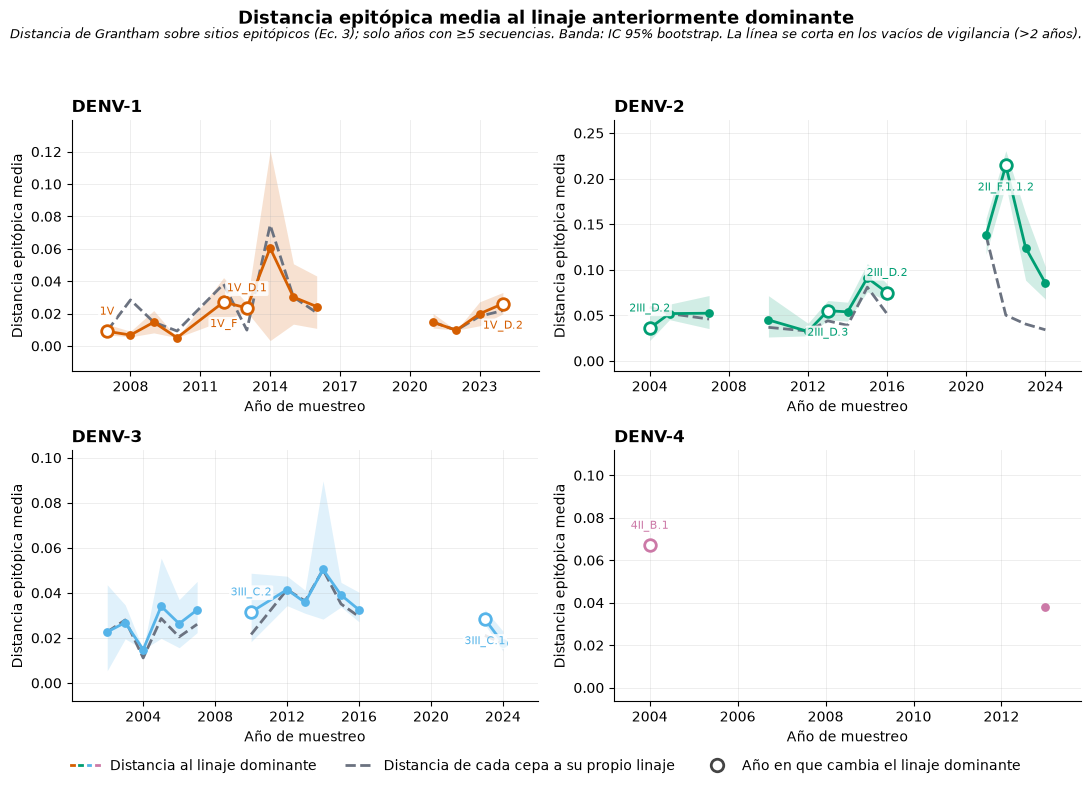


DENV1
 year  n lin_prev    dom  cambio  media  propio
 2007 13     1V_G     1V    True  0.009   0.009
 2008 15       1V     1V   False  0.007   0.028
 2009  7       1V     1V   False  0.015   0.015
 2010  9       1V     1V   False  0.005   0.009
 2012 14       1V   1V_F    True  0.027   0.038
 2013 87     1V_F 1V_D.1    True  0.023   0.010
 2014  5   1V_D.1 1V_D.1   False  0.060   0.075
 2015  9   1V_D.1 1V_D.1   False  0.030   0.030
 2016 17   1V_D.1 1V_D.1   False  0.024   0.021
 2021 19   1V_D.1 1V_D.1   False  0.015   0.015
 2022  7   1V_D.1 1V_D.1   False  0.010   0.010
 2023 21   1V_D.1 1V_D.1   False  0.020   0.018
 2024 37   1V_D.1 1V_D.2    True  0.026   0.022

DENV2
 year   n    lin_prev         dom  cambio  media  propio
 2004   5    2III_D.3    2III_D.2    True  0.036   0.059
 2005  19    2III_D.2    2III_D.2   False  0.052   0.052
 2007  11    2III_D.2    2III_D.2   False  0.052   0.046
 2010   6    2III_D.2    2III_D.2   False  0.045   0.037
 2012  18    2III_D.2    2III

In [101]:

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
series_linaje = {}

for ax, sero in zip(axes.ravel(), [1, 2, 3, 4]):
    C_PREV = SERO_COLORS[sero]
    t = series_linaje[sero] = serie_linaje(sero)
    if t.empty:
        ax.set_axis_off()
        continue

    # la línea se corta en los vacíos de vigilancia
    for _, tr in t.groupby(t.year.diff().gt(2).cumsum()):
        ax.fill_between(tr.year, tr.lo, tr.hi, color=C_PREV, alpha=0.18, lw=0)
        ax.plot(tr.year, tr.media, "-", color=C_PREV, lw=2, zorder=3)
        ax.plot(tr.year, tr.propio, "--", color=C_SELF, lw=2, zorder=2)

    camb = t[t.cambio]
    ax.scatter(camb.year, camb.media, s=70, facecolor="white",
               edgecolor=C_PREV, lw=2, zorder=4)
    ax.scatter(t[~t.cambio].year, t[~t.cambio].media, s=28, color=C_PREV, zorder=4)
    for k, (_, r) in enumerate(camb.iterrows()):
        ax.annotate(r["dom"], (r.year, r.media), textcoords="offset points",
                    xytext=(0, 12 if k % 2 == 0 else -18), ha="center",
                    fontsize=8, color=C_PREV, annotation_clip=False, zorder=6,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))

    ax.set_title(f"DENV-{sero}", fontsize=12, fontweight="bold", loc="left")
    ax.set_xlabel("Año de muestreo", fontsize=10)
    ax.set_ylabel("Distancia epitópica media", fontsize=10)
    ax.grid(alpha=0.25, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True, nbins=7))
    ax.margins(x=0.09, y=0.16)

h = [tuple(plt.Line2D([], [], color=SERO_COLORS[s], lw=2) for s in (1, 2, 3, 4)),
     plt.Line2D([], [], color=C_SELF, lw=2, ls="--"),
     plt.Line2D([], [], marker="o", ls="", mfc="white", mec="#444444", mew=2, ms=9)]
fig.legend(handles=h,
           labels=["Distancia al linaje dominante",
                   "Distancia de cada cepa a su propio linaje",
                   "Año en que cambia el linaje dominante"],
           handler_map={tuple: matplotlib.legend_handler.HandlerTuple(ndivide=None, pad=0.4)},
           loc="lower center", ncol=3, frameon=False, fontsize=10,
           bbox_to_anchor=(0.5, -0.035))

fig.suptitle("Distancia epitópica media al linaje anteriormente dominante",
             fontsize=13, fontweight="bold", y=1.0)
fig.text(0.5, 0.962,
         f"Distancia de Grantham sobre sitios epitópicos (Ec. 3); solo años con ≥{MIN_N} secuencias. "
         "Banda: IC 95% bootstrap. La línea se corta en los vacíos de vigilancia (>2 años).",
         ha="center", fontsize=9, style="italic")
fig.tight_layout(rect=[0, 0, 1, 0.945])
fig.savefig("../figures/distancia_linaje_previo.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

for sero, t in series_linaje.items():
    print(f"\nDENV{sero}")
    print(t[["year", "n", "lin_prev", "dom", "cambio", "media", "propio"]]
          .round(3).to_string(index=False))
print("\n  Guardado: distancia_linaje_previo.png")
